# Tianeptine – OGD bulk RNA-seq: Differential expression analysis

**Data:** Filtered gene-level counts from notebook 01 (18,665 genes × 16 samples).

**Aim:** Identify genes differentially expressed between experimental groups using PyDESeq2, the Python implementation of DESeq2.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from matplotlib_venn import venn2

## 1. Load data

In [2]:
counts = pd.read_csv("../results/gene_counts_filtered.csv", index_col=0)
counts.shape


(18665, 16)

In [3]:
metadata = pd.read_csv("../data/metadata.csv", index_col="sample")
metadata

,geo_accession,group,condition,treatment
sample,,,,
X1,GSM7474909,CONTROL-VEH,CONTROL,VEH
X2,GSM7474910,CONTROL-VEH,CONTROL,VEH
X3,GSM7474911,CONTROL-VEH,CONTROL,VEH
X4,GSM7474912,CONTROL-VEH,CONTROL,VEH
X5,GSM7474913,CONTROL-TIA,CONTROL,TIA
X6,GSM7474914,CONTROL-TIA,CONTROL,TIA
X7,GSM7474915,CONTROL-TIA,CONTROL,TIA
X8,GSM7474916,CONTROL-TIA,CONTROL,TIA
X9,GSM7474917,OGD-VEH,OGD,VEH


## 2. Prepare data for PyDESeq2

PyDESeq2 requires integer counts with samples as rows and genes as columns. Estimated transcript counts were summed per gene, so they are rounded to the nearest integer.

In [4]:
counts_deseq = counts.round().astype(int).T
counts_deseq.shape

(16, 18665)

In [5]:
(counts_deseq.index == metadata.index).all()

np.True_

## 3. Differential expression with PyDESeq2

In [6]:
dds = DeseqDataSet(counts=counts_deseq, metadata=metadata, design="~group")

In [7]:
dds

AnnData object with n_obs × n_vars = 16 × 18665
    obs: 'geo_accession', 'group', 'condition', 'treatment'
    obsm: 'design_matrix'
    layers: None (.X)

In [8]:
dds.deseq2()

Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.01 seconds.

Fitting dispersions...
... done in 1.46 seconds.

Fitting dispersion trend curve...
... done in 0.20 seconds.

Fitting MAP dispersions...
... done in 1.88 seconds.

Fitting LFCs...
... done in 1.01 seconds.

Calculating cook's distance...
... done in 0.02 seconds.

Replacing 0 outlier genes.



#### Helper function: volcano plot

A volcano plot function is defined once here and used for each comparison below.

In [9]:
def plot_volcano(res, title):
    res_plot = res.dropna(subset=["padj"]).copy()
    res_plot["neg_log10_padj"] = -np.log10(res_plot["padj"])

    res_plot["status"] = "Not significant"
    res_plot.loc[(res_plot["padj"] <= 0.05) & (res_plot["log2FoldChange"] >= 1),
                 "status"] = "Up"
    res_plot.loc[(res_plot["padj"] <= 0.05) & (res_plot["log2FoldChange"] <= -1),
                 "status"] = "Down"
    
    status_colors = {
        "Not significant": "lightgray",
        "Up": "#d6453d",
        "Down": "#2a78d6",
    }

    fig, ax = plt.subplots(figsize=(7, 6))

    for status, color in status_colors.items():
        genes = res_plot[res_plot["status"] == status]
        ax.scatter(genes["log2FoldChange"], genes["neg_log10_padj"],
                   color=color, label=f"{status} ({len(genes)})", s=8)

    ax.axhline(-np.log10(0.05), color="black", linestyle="--", linewidth=0.8)
    ax.axvline(-1, color="black", linestyle="--", linewidth=0.8)
    ax.axvline(1, color="black", linestyle="--", linewidth=0.8)

    ax.set_xlabel("log2 fold change")
    ax.set_ylabel("-log10(adjusted p-value)")
    ax.set_title(title)
    ax.legend(loc="upper left")
    plt.show()

### 3.1 OGD vs control (vehicle-treated)

Comparison: OGD-VEH vs CONTROL-VEH. Which genes are changed by OGD?

In [10]:
ds_ogd = DeseqStats(dds, contrast=["group", "OGD-VEH", "CONTROL-VEH"])

In [11]:
ds_ogd.summary()

Running Wald tests...


Log2 fold change & Wald test p-value: group OGD-VEH vs CONTROL-VEH
                  baseMean  log2FoldChange     lfcSE      stat    pvalue  \
Gene Symbol                                                                
0610006L08Rik    12.526822       -0.586977  0.416035 -1.410884  0.158279   
0610009B22Rik   605.047693        0.076299  0.133024  0.573569  0.566260   
0610009E02Rik    58.828352       -0.468937  0.209025 -2.243452  0.024868   
0610009L18Rik   142.513047       -0.413774  0.203116 -2.037125  0.041637   
0610009O20Rik  1100.414828        0.199596  0.084528  2.361314  0.018210   
...                    ...             ...       ...       ...       ...   
mt-Ti            11.338415       -0.984508  0.506274 -1.944615  0.051821   
mt-Tl1           48.621529        0.174226  0.334413  0.520992  0.602373   
mt-Tm            18.471246       -0.132773  0.401741 -0.330495  0.741026   
mt-Tw            36.282608       -0.243885  0.385979 -0.631861  0.527478   
n-R5-8s1         11.3

... done in 0.46 seconds.



In [12]:
res_ogd = ds_ogd.results_df
res_ogd.shape

(18665, 6)

In [13]:
sig_ogd = res_ogd[(res_ogd["padj"] <= 0.05) & (res_ogd["log2FoldChange"].abs() >= 1)]
len(sig_ogd)

1832

**Result:** 1,832 genes are differentially expressed between OGD-VEH and CONTROL-VEH (padj ≤ 0.05, |log2FC| ≥ 1).

In [14]:
n_up = (sig_ogd["log2FoldChange"] > 0).sum()
n_down = (sig_ogd["log2FoldChange"] < 0).sum()
print("Up-regulated:", n_up)
print("Down-regulated:", n_down)

Up-regulated: 934
Down-regulated: 898


Of these, 934 genes are up-regulated and 898 are down-regulated after OGD.

In [15]:
sig_ogd.sort_values("padj").head(20)

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
Gene Symbol,,,,,,
Emp1,600.443664,4.604074,0.419077,10.986234,4.451152e-28,8.305850e-24
Slc30a3,60.580041,-2.398296,0.246630,-9.724282,2.375745e-22,1.899456e-18
Gbp2,182.328112,5.068256,0.522571,9.698695,3.053788e-22,1.899456e-18
Med22,2291.360020,1.034689,0.121426,8.521180,1.579358e-17,4.210118e-14
Trp53,2131.595687,1.356215,0.160937,8.427014,3.545960e-17,7.351956e-14
Gm6485,2599.934445,1.234153,0.148840,8.291796,1.115508e-16,2.081538e-13
Cd44,1237.492556,3.167536,0.397012,7.978432,1.482041e-15,1.931172e-12
Timp1,55.836128,4.185174,0.524938,7.972705,1.552389e-15,1.931172e-12
Ifi209,34.866785,4.974754,0.628490,7.915411,2.464383e-15,2.874087e-12


**Observation:** The 20 most significant genes are dominated by up-regulated genes (18/20). They include genes involved in the cellular stress and cell-death response (*Trp53*, *Eif4ebp1*, *Hmga2*, *Id1*) and a prominent group of inflammation- and interferon-related genes (*Gbp2*, *Ifi209*, *Cxcl10*, *Lgals3*, *Lgals1*, *Cd44*, *Timp1*). Some of these inflammatory genes are typically expressed by glial cells, so part of this signal may originate from residual glia in the primary neuronal cultures. Among the down-regulated genes, *Slc30a3* (ZnT3, a neuron-specific synaptic vesicle zinc transporter) decreases ~5-fold, consistent with reduced synaptic function after OGD.

#### Volcano plot

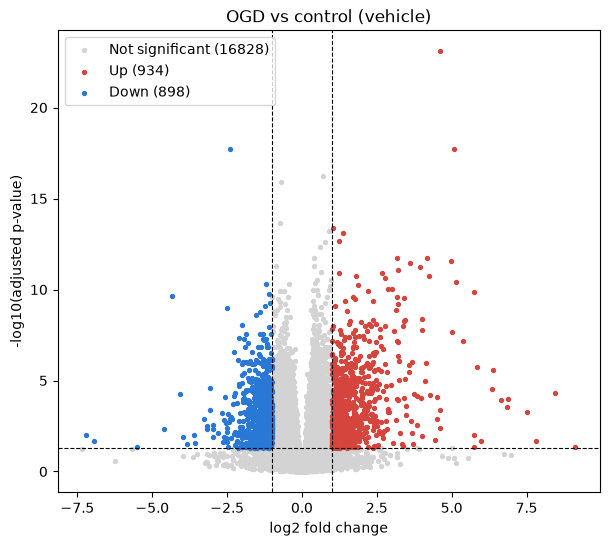

In [16]:
plot_volcano(res_ogd, "OGD vs control (vehicle)")

**Observation:** The volcano plot shows a broad and roughly symmetric transcriptional response to OGD, with 934 up-regulated (red) and 898 down-regulated (blue) genes. The most significant changes are among up-regulated genes (e.g. *Emp1*, ~24-fold, padj ≈ 10⁻²⁴). Many genes in the centre are highly significant but change less than two-fold and are therefore not counted as differentially expressed.

### 3.2 Tianeptine vs vehicle under OGD

Comparison: OGD-TIA vs OGD-VEH. Which genes does tianeptine change after OGD?

In [17]:
ds_tia = DeseqStats(dds, contrast=["group", "OGD-TIA", "OGD-VEH"])
ds_tia.summary()

Running Wald tests...


Log2 fold change & Wald test p-value: group OGD-TIA vs OGD-VEH
                  baseMean  log2FoldChange     lfcSE      stat    pvalue  \
Gene Symbol                                                                
0610006L08Rik    12.526822        0.333421  0.419371  0.795052  0.426584   
0610009B22Rik   605.047693       -0.003587  0.132528 -0.027066  0.978407   
0610009E02Rik    58.828352        0.421195  0.207692  2.027976  0.042563   
0610009L18Rik   142.513047       -0.150115  0.205676 -0.729863  0.465474   
0610009O20Rik  1100.414828       -0.100568  0.084045 -1.196589  0.231467   
...                    ...             ...       ...       ...       ...   
mt-Ti            11.338415        0.386426  0.517847  0.746217  0.455537   
mt-Tl1           48.621529       -0.429866  0.335656 -1.280673  0.200308   
mt-Tm            18.471246        0.738601  0.385236  1.917267  0.055204   
mt-Tw            36.282608       -0.685120  0.397177 -1.724974  0.084532   
n-R5-8s1         11.30526

... done in 0.47 seconds.



In [18]:
res_tia = ds_tia.results_df

sig_tia = res_tia[(res_tia["padj"] <= 0.05) & (res_tia["log2FoldChange"].abs() >= 1)]

print("Significant genes:", len(sig_tia))
print("Up-regulated:", (sig_tia["log2FoldChange"] > 0).sum())
print("Down-regulated:", (sig_tia["log2FoldChange"] < 0).sum())

Significant genes: 6
Up-regulated: 3
Down-regulated: 3


**Result:** Only 6 genes are differentially expressed between OGD-TIA and OGD-VEH (3 up, 3 down). This low number is likely due to high within-group variability: in each OGD group, one sample (X9 in OGD-VEH, X16 in OGD-TIA) resembles the other group (see PCA). A sensitivity analysis is performed below.

In [19]:
sig_tia.sort_values("padj")

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
Gene Symbol,,,,,,
Scn9a,51.647128,2.611510,0.611953,4.267503,0.000020,0.017457
Syt10,60.871742,1.278918,0.309199,4.136229,0.000035,0.022536
Hmga2,101.092223,-1.791895,0.437317,-4.097471,0.000042,0.024254
Gm3488,149.505222,1.086238,0.273707,3.968611,0.000072,0.034066
Gadd45b,113.420823,-1.177034,0.305145,-3.857289,0.000115,0.042080
Emp3,57.558692,-2.134332,0.562814,-3.792250,0.000149,0.049014


In [20]:
pd.DataFrame({
    "LFC_OGD_vs_CTRL": res_ogd.loc[sig_tia.index, "log2FoldChange"],
    "LFC_TIA_vs_VEH": sig_tia["log2FoldChange"],
})

,LFC_OGD_vs_CTRL,LFC_TIA_vs_VEH
Gene Symbol,,
Emp3,4.018603,-2.134332
Gadd45b,1.774691,-1.177034
Gm3488,-0.912185,1.086238
Hmga2,3.600051,-1.791895
Scn9a,-4.337621,2.611510
Syt10,-2.003037,1.278918


#### Volcano plot

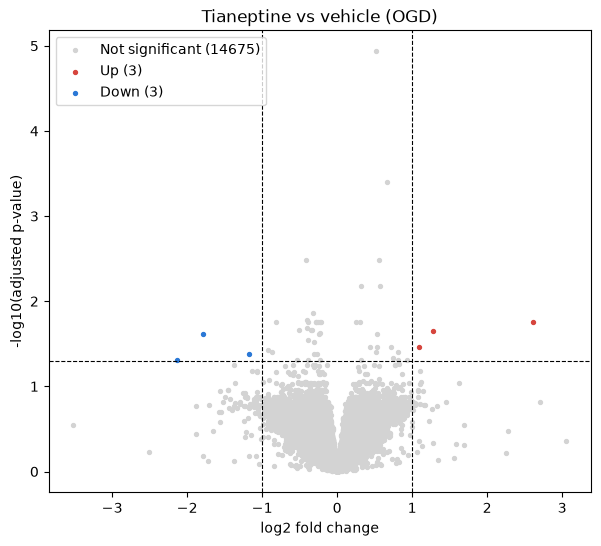

In [21]:
plot_volcano(res_tia, "Tianeptine vs vehicle (OGD)")

**Observation:** The volcano plot shows a much weaker response than after OGD (note the different axis scales: max −log10(padj) ≈ 5 vs ≈ 23). About 4,000 low-expressed genes were excluded by DESeq2's independent filtering. Several genes are significant (padj < 0.05) but change less than two-fold, indicating small but consistent effects of tianeptine that are missed by the |log2FC| ≥ 1 threshold.

### 3.3 Tianeptine vs vehicle under control conditions

Comparison: CONTROL-TIA vs CONTROL-VEH. Does tianeptine alone change gene expression?

In [22]:
ds_ctrl = DeseqStats(dds, contrast=["group", "CONTROL-TIA", "CONTROL-VEH"])
ds_ctrl.summary()

Running Wald tests...


Log2 fold change & Wald test p-value: group CONTROL-TIA vs CONTROL-VEH
                  baseMean  log2FoldChange     lfcSE      stat    pvalue  \
Gene Symbol                                                                
0610006L08Rik    12.526822       -0.137112  0.395872 -0.346356  0.729075   
0610009B22Rik   605.047693        0.041553  0.132958  0.312531  0.754637   
0610009E02Rik    58.828352       -0.107949  0.201982 -0.534449  0.593031   
0610009L18Rik   142.513047       -0.130573  0.200904 -0.649927  0.515739   
0610009O20Rik  1100.414828       -0.035848  0.084858 -0.422451  0.672696   
...                    ...             ...       ...       ...       ...   
mt-Ti            11.338415       -0.790826  0.495871 -1.594822  0.110752   
mt-Tl1           48.621529       -0.000099  0.335556 -0.000296  0.999764   
mt-Tm            18.471246       -0.063968  0.397928 -0.160753  0.872288   
mt-Tw            36.282608       -0.102121  0.383483 -0.266297  0.790010   
n-R5-8s1         

... done in 0.46 seconds.



In [23]:
res_ctrl = ds_ctrl.results_df

sig_ctrl = res_ctrl[(res_ctrl["padj"] <= 0.05) & (res_ctrl["log2FoldChange"].abs() >= 1)]

print("Significant genes:", len(sig_ctrl))
print("Up-regulated:", (sig_ctrl["log2FoldChange"] > 0).sum())
print("Down-regulated:", (sig_ctrl["log2FoldChange"] < 0).sum())

Significant genes: 0
Up-regulated: 0
Down-regulated: 0


**Result:** No genes are differentially expressed between CONTROL-TIA and CONTROL-VEH (padj ≈ 1 for nearly all genes). Tianeptine alone does not detectably alter the neuronal transcriptome under normoxic conditions, consistent with the intermixing of these groups in PCA and clustering. Given the low within-group variability of control samples, large effects are unlikely to have been missed.

#### Volcano plot

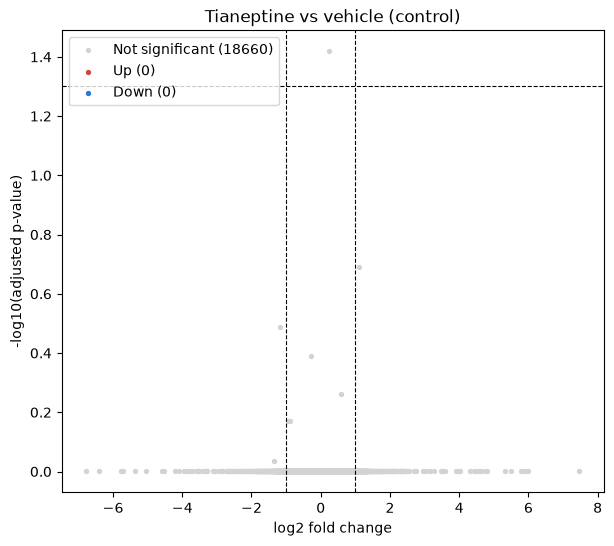

In [24]:
plot_volcano(res_ctrl, "Tianeptine vs vehicle (control)")

**Observation:** Nearly all genes have padj ≈ 1 (−log10 ≈ 0). Some genes show large fold changes (|log2FC| up to ~8) but are far from significant; these are low-count, noisy genes, illustrating that fold changes alone are unreliable without statistical support. A single gene reaches padj < 0.05 but changes by less than 25%. Tianeptine alone does not detectably alter gene expression.

### 3.4 OGD vs control (tianeptine-treated)

Comparison: OGD-TIA vs CONTROL-TIA. Which genes are changed by OGD in the presence of tianeptine?

In [25]:
ds_ogd_tia = DeseqStats(dds, contrast=["group", "OGD-TIA", "CONTROL-TIA"])
ds_ogd_tia.summary()

Running Wald tests...


Log2 fold change & Wald test p-value: group OGD-TIA vs CONTROL-TIA
                  baseMean  log2FoldChange     lfcSE      stat    pvalue  \
Gene Symbol                                                                
0610006L08Rik    12.526822       -0.116443  0.399376 -0.291564  0.770620   
0610009B22Rik   605.047693        0.031158  0.132461  0.235226  0.814034   
0610009E02Rik    58.828352        0.060207  0.200603  0.300132  0.764077   
0610009L18Rik   142.513047       -0.433316  0.203492 -2.129400  0.033221   
0610009O20Rik  1100.414828        0.134877  0.084377  1.598499  0.109932   
...                    ...             ...       ...       ...       ...   
mt-Ti            11.338415        0.192744  0.507681  0.379656  0.704201   
mt-Tl1           48.621529       -0.255541  0.336796 -0.758740  0.448008   
mt-Tm            18.471246        0.669796  0.381259  1.756801  0.078952   
mt-Tw            36.282608       -0.826884  0.394752 -2.094695  0.036198   
n-R5-8s1         11.3

... done in 0.42 seconds.



In [26]:
res_ogd_tia = ds_ogd_tia.results_df

sig_ogd_tia = res_ogd_tia[(res_ogd_tia["padj"] <= 0.05) & (res_ogd_tia["log2FoldChange"].abs() >= 1)]

print("Significant genes:", len(sig_ogd_tia))
print("Up-regulated:", (sig_ogd_tia["log2FoldChange"] > 0).sum())
print("Down-regulated:", (sig_ogd_tia["log2FoldChange"] < 0).sum())

Significant genes: 292
Up-regulated: 151
Down-regulated: 141


**Result:** 292 genes are differentially expressed between OGD-TIA and CONTROL-TIA (151 up, 141 down), compared with 1,832 genes after OGD in vehicle-treated cultures (3.1). This ~84% reduction is consistent with tianeptine attenuating the transcriptional response to OGD. However, the number of significant genes also depends on within-group variability, which is higher in the OGD-TIA group due to sample X16. Fold changes are therefore compared directly below.

*Comparison with the published analysis (Ersoy et al., 2024):* 1,675 DEGs (OGD-VEH vs CONTROL-VEH) and 445 DEGs (OGD-TIA vs CONTROL-TIA), using the same thresholds. Our re-analysis reproduces the main finding: tianeptine strongly reduces the number of OGD-regulated genes.

#### Volcano plot

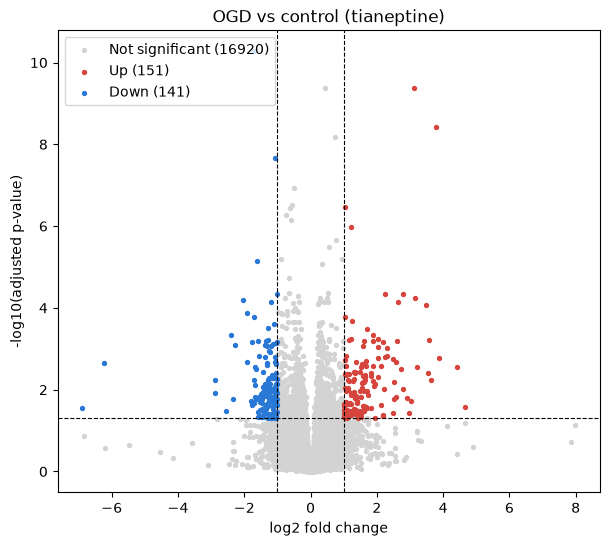

In [27]:
plot_volcano(res_ogd_tia, "OGD vs control (tianeptine)")

**Observation:** In the presence of tianeptine, OGD induces a qualitatively similar but much weaker response than in vehicle-treated cultures (3.1): fewer genes pass the thresholds (292 vs 1,832) and significance values are lower (max −log10(padj) ≈ 9 vs ≈ 23). This is consistent with tianeptine attenuating the OGD response, although higher variability in the OGD-TIA group (sample X16) also contributes.

## 4. Effect of tianeptine on the OGD response

The OGD response is compared between vehicle- and tianeptine-treated cultures (3.1 vs 3.4), following the approach of the original study.

In [28]:
genes_veh = set(sig_ogd.index)
genes_tia = set(sig_ogd_tia.index)

print("OGD genes in vehicle:", len(genes_veh))
print("OGD genes in tianeptine:", len(genes_tia))

OGD genes in vehicle: 1832
OGD genes in tianeptine: 292


In [29]:
shared = genes_veh & genes_tia
only_veh = genes_veh - genes_tia
only_tia = genes_tia - genes_veh

print("Shared:", len(shared))
print("Only in vehicle:", len(only_veh))
print("Only in tianeptine:", len(only_tia))

Shared: 236
Only in vehicle: 1596
Only in tianeptine: 56


**Overlap:** 236 genes respond to OGD in both conditions, 1,596 only in vehicle and 56 only in tianeptine-treated cultures. Most OGD-responsive genes in the presence of tianeptine (81%) are also OGD-responsive in vehicle, i.e. tianeptine does not induce a distinct transcriptional programme but reduces the OGD response. Published analysis: 318 shared, 1,357 vehicle-only, 127 tianeptine-only. Note that "only in vehicle" does not prove protection, since genes may change below the significance threshold in tianeptine-treated cultures; fold changes are compared below.

#### Venn diagram

Overlap between genes differentially expressed after OGD in vehicle- and tianeptine-treated cultures.

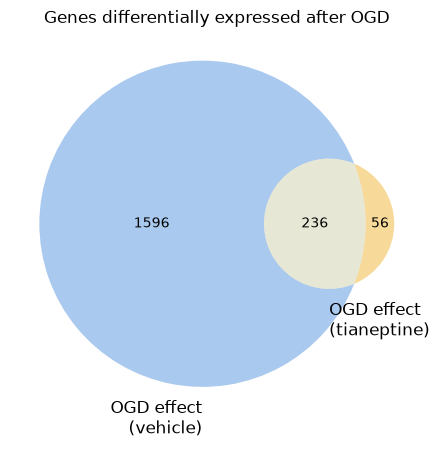

In [30]:
fig, ax = plt.subplots(figsize=(6, 5))
venn2([genes_veh, genes_tia],
      set_labels=("OGD effect\n(vehicle)", "OGD effect\n(tianeptine)"),
      set_colors=("#2a78d6", "#eda100"),
      ax=ax)
ax.set_title("Genes differentially expressed after OGD")
plt.show()

**Observation:** The tianeptine circle lies almost entirely within the vehicle circle: most genes responding to OGD in the presence of tianeptine (236/292, 81%) also respond in its absence, whereas the majority of OGD-responsive genes in vehicle (1,596) are no longer significantly changed with tianeptine. None of the shared genes shows a reliable reversal of direction between conditions.

*Limitation:* A Venn diagram only shows whether a gene passes the significance threshold. It does not show the size or direction of the change, so "vehicle-only" genes are not necessarily protected. Fold changes are compared directly below.

#### Comparison of OGD effects

For each gene, the OGD effect in vehicle-treated cultures (x) is plotted against the OGD effect in tianeptine-treated cultures (y). Points below the diagonal indicate an attenuated OGD response with tianeptine.

In [31]:
lfc = pd.DataFrame({
    "vehicle": res_ogd["log2FoldChange"],
    "tianeptine": res_ogd_tia["log2FoldChange"],
})
lfc.head()

,vehicle,tianeptine
Gene Symbol,,
0610006L08Rik,-0.586977,-0.116443
0610009B22Rik,0.076299,0.031158
0610009E02Rik,-0.468937,0.060207
0610009L18Rik,-0.413774,-0.433316
0610009O20Rik,0.199596,0.134877


In [32]:
lfc["category"] = "Not significant"
lfc.loc[lfc.index.isin(only_veh), "category"] = "Only vehicle"
lfc.loc[lfc.index.isin(shared), "category"] = "Both"
lfc.loc[lfc.index.isin(only_tia), "category"] = "Only tianeptine"
lfc["category"].value_counts()

category
Not significant    16777
Only vehicle        1596
Both                 236
Only tianeptine       56
Name: count, dtype: int64

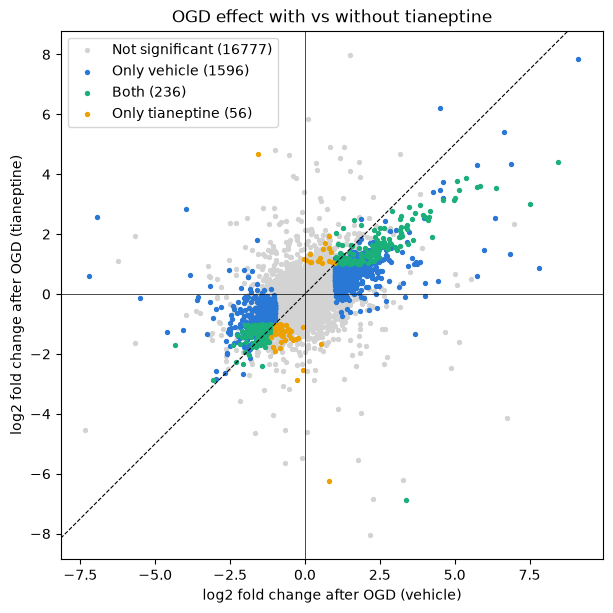

In [33]:
category_colors = {
    "Not significant": "lightgray",
    "Only vehicle": "#2a78d6",
    "Both": "#1baf7a",
    "Only tianeptine": "#eda100",
}

fig, ax = plt.subplots(figsize=(7, 7))

for category, color in category_colors.items():
    genes = lfc[lfc["category"] == category]
    ax.scatter(genes["vehicle"], genes["tianeptine"],
               color=color, label=f"{category} ({len(genes)})", s=8)

ax.axline((0, 0), slope=1, color="black", linestyle="--", linewidth=0.8)
ax.axhline(0, color="black", linewidth=0.5)
ax.axvline(0, color="black", linewidth=0.5)
ax.set_aspect("equal")

ax.set_xlabel("log2 fold change after OGD (vehicle)")
ax.set_ylabel("log2 fold change after OGD (tianeptine)")
ax.set_title("OGD effect with vs without tianeptine")
ax.legend(loc="upper left")
plt.show()

**Observation:** Genes significant only in vehicle (blue) mostly lie well below the diagonal, close to the x-axis: their OGD response is strongly attenuated, not merely below threshold, in tianeptine-treated cultures. Genes significant in both conditions (green) also tend to lie slightly below the diagonal, indicating partial attenuation. Genes significant only with tianeptine (orange) show small, same-direction changes in vehicle, consistent with threshold effects rather than a tianeptine-specific programme. Overall, the cloud of OGD-responsive genes is flatter than the diagonal, indicating a systematic, transcriptome-wide attenuation of the OGD response by tianeptine. *Caveat:* selecting genes by significance in vehicle inflates their vehicle fold changes ("winner's curse"), which may exaggerate this pattern; an interaction test addresses this.

#### Interaction test

Tests for each gene whether the OGD effect differs between tianeptine- and vehicle-treated cultures: (OGD-TIA − CONTROL-TIA) − (OGD-VEH − CONTROL-VEH).

In [34]:
dds.obsm["design_matrix"].columns

Index(['Intercept', 'group[T.CONTROL-VEH]', 'group[T.OGD-TIA]',
       'group[T.OGD-VEH]'],
      dtype='str')

In [35]:
interaction = np.array([0, 1, 1, -1])

ds_int = DeseqStats(dds, contrast=interaction)
ds_int.summary()

Running Wald tests...


Log2 fold change & Wald test p-value, contrast vector: [ 0  1  1 -1]
                  baseMean  log2FoldChange     lfcSE      stat    pvalue  \
Gene Symbol                                                                
0610006L08Rik    12.526822        0.470534  0.576703  0.815903  0.414555   
0610009B22Rik   605.047693       -0.045140  0.187727 -0.240457  0.809976   
0610009E02Rik    58.828352        0.529144  0.289712  1.826451  0.067782   
0610009L18Rik   142.513047       -0.019542  0.287516 -0.067969  0.945810   
0610009O20Rik  1100.414828       -0.064719  0.119434 -0.541884  0.587899   
...                    ...             ...       ...       ...       ...   
mt-Ti            11.338415        1.177253  0.716975  1.641970  0.100596   
mt-Tl1           48.621529       -0.429767  0.474619 -0.905498  0.365201   
mt-Tm            18.471246        0.802569  0.553854  1.449064  0.147320   
mt-Tw            36.282608       -0.582999  0.552095 -1.055976  0.290979   
n-R5-8s1         11

... done in 0.38 seconds.



In [36]:
res_int = ds_int.results_df

check_genes = ["Hmga2", "Emp1", "Atf3", "Trp53", "Serpine1", "Hif1a", "Adamts7"]
pd.DataFrame({
    "OGD_vehicle": res_ogd.loc[check_genes, "log2FoldChange"],
    "OGD_tianeptine": res_ogd_tia.loc[check_genes, "log2FoldChange"],
    "interaction": res_int.loc[check_genes, "log2FoldChange"],
    "interaction_padj": res_int.loc[check_genes, "padj"],
})



,OGD_vehicle,OGD_tianeptine,interaction,interaction_padj
Gene Symbol,,,,
Hmga2,3.600051,1.817125,-1.782926,0.682554
Emp1,4.604074,3.124345,-1.479729,0.682554
Atf3,3.090318,1.468049,-1.622269,0.682554
Trp53,1.356215,0.780253,-0.575961,0.682554
Serpine1,3.441331,0.938701,-2.502630,0.682554
Hif1a,0.115154,-0.047710,-0.162864,0.682554
Adamts7,1.093447,0.653128,-0.440319,0.703652


**Gene functions (brief literature context):**

- *Trp53* (p53): tumour suppressor activated by DNA damage and cellular stress; induces cell-cycle arrest or apoptosis and contributes to neuronal death after ischaemia.
- *Serpine1* (PAI-1): inhibitor of tissue- and urokinase-type plasminogen activators (tPA/uPA), thereby limiting fibrinolysis; hypoxia-inducible and implicated in blood–brain barrier function after stroke.
- *Atf3*: immediate-early, stress-inducible transcription factor; strongly induced by ischaemia and axonal injury, with reported protective and injury-associated roles.
- *Hmga2*: chromatin-architectural protein that regulates gene expression; high in development and stem cells, associated with proliferation and EMT in cancer.
- *Emp1*: membrane protein involved in cell–cell contact, proliferation and migration; induced after tissue injury and a marker of invasive/mesenchymal glioblastoma cells.
- *Hif1a* (HIF-1α): master regulator of the hypoxia response, regulated mainly at the protein level (stabilised under hypoxia), so its mRNA need not increase; *Serpine1* is a HIF target.
- *Adamts7*, *Mmp3*: extracellular-matrix-degrading metalloproteinases; *Mmp3* is expressed mainly by glial and endothelial cells, consistent with its absence in neuronal cultures.

Together, the genes attenuated by tianeptine relate to cell death (*Trp53*), stress signalling (*Atf3*), the hypoxia response (*Serpine1*) and tissue remodelling (*Hmga2*, *Emp1*), suggesting that tianeptine dampens an OGD-induced injury programme. This will be tested systematically by pathway analysis.

#### Summary of section 4

- **Number of OGD-regulated genes:** OGD changes 1,832 genes in vehicle-treated but only 292 genes in tianeptine-treated cultures; 81% of the latter also respond in vehicle (Venn diagram).
- **Effect sizes:** Genes significant only in vehicle mostly show a strongly reduced OGD response with tianeptine, and shared genes show partial attenuation (fold-change comparison).
- **Single-gene interaction tests:** Interaction estimates are consistently negative for OGD-induced genes (e.g. *Serpine1*, *Hmga2*, *Atf3*, *Trp53*), but none is statistically significant, reflecting limited power (n = 4 per group, high variability in OGD groups).
- **Independent validation:** qPCR from the original study confirms the OGD-induced increase of *Trp53* and *Serpine1* and its attenuation by tianeptine.

**Conclusion:** The data consistently indicate that tianeptine attenuates, but does not abolish, the transcriptional response to OGD. This is supported by PCA, the fold-change comparison and independent qPCR, although it cannot be established for individual genes with the present sample size.

## 5. Save results

DE result tables are saved for pathway analysis (notebook 03).

In [37]:
res_ogd.to_csv("../results/DE_OGD_vs_CTRL_vehicle.csv")
res_tia.to_csv("../results/DE_TIA_vs_VEH_OGD.csv")
res_ctrl.to_csv("../results/DE_TIA_vs_VEH_control.csv")
res_ogd_tia.to_csv("../results/DE_OGD_vs_CTRL_tianeptine.csv")
res_int.to_csv("../results/DE_interaction.csv")